In [67]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [68]:
data = pd.read_csv("Admission_Predict.csv")
data.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65


In [69]:
print("Shape:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())

Shape: (400, 9)

Missing values:
Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             3
Chance of Admit      0
dtype: int64


In [70]:
data = data.fillna(data.mode().iloc[0])
print(data.isnull().sum())

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64


In [71]:
new_data = data.drop(columns = "Serial No.")

In [72]:
print(data.isnull().sum())

Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64


In [73]:
print(data.columns)

Index(['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR', 'CGPA', 'Research', 'Chance of Admit'],
      dtype='object')


In [74]:
new_data.dtypes

GRE Score              int64
TOEFL Score            int64
University Rating      int64
SOP                  float64
LOR                  float64
CGPA                 float64
Research             float64
Chance of Admit      float64
dtype: object

In [75]:
new_data["admitted"] = np.where(new_data["Chance of Admit"] <= 0.85, 0, 1)

In [76]:
new_data

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,admitted
0,337,118,4,4.5,4.5,9.65,1.0,0.92,1
1,324,107,4,4.0,4.5,8.87,1.0,0.76,0
2,316,104,3,3.0,3.5,8.00,1.0,0.72,0
3,322,110,3,3.5,2.5,8.67,1.0,0.80,0
4,314,103,2,2.0,3.0,8.21,0.0,0.65,0
...,...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0.82,0
396,325,107,3,3.0,3.5,9.11,1.0,0.84,0
397,330,116,4,5.0,4.5,9.45,1.0,0.91,1
398,312,103,3,3.5,4.0,8.78,0.0,0.67,0


In [77]:
data = new_data.drop(columns = "Chance of Admit")

In [78]:
x = data[
    ["GRE Score",
     "TOEFL Score",
     "University Rating",
     "SOP",
     "LOR",
     "CGPA",
     "Research"
    ]]
y = data["admitted"]

In [79]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.20, random_state=0)

In [80]:
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (320, 7)
Testing data: (80, 7)


In [81]:
from sklearn.tree import DecisionTreeClassifier

In [82]:
dt = DecisionTreeClassifier(criterion="entropy")

In [83]:
dt.fit(x_train,y_train)

,criterion,'entropy'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [84]:
prediction = dt.predict(x_test)

In [85]:
prediction

array([0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0])

In [86]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score

In [87]:
print("\nConfusion Matrix")
cm = confusion_matrix( y_test,prediction)
print(cm)

print("\nAccuracy Score")
acc = accuracy_score(y_test, prediction)
print(acc)

print("\nPrecision")
precision = precision_score(y_test,prediction, average='weighted')
print(precision)

print("\nRecall")
recall = recall_score(y_test, prediction, average='weighted')
print(recall)



Confusion Matrix
[[61  3]
 [ 3 13]]

Accuracy Score
0.925

Precision
0.925

Recall
0.925


In [88]:
from sklearn.tree import plot_tree

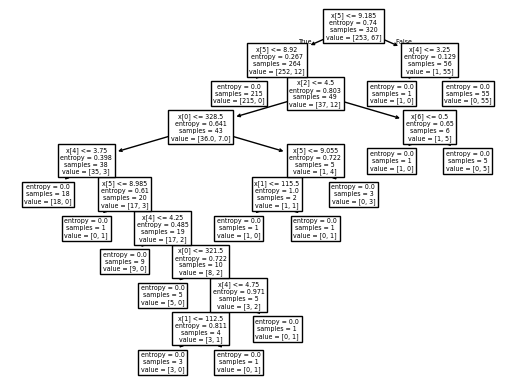

In [89]:
tree = plot_tree(dt)

In [90]:
data

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,admitted
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [91]:
print("Enter the details")
gre = float(input("GRE Score :"))
toefl = float(input("TOEFL Score :"))
rating = float(input("University Rating :"))
sop = float(input("SOP :"))
lor = float(input("LOR :"))
cgpa = float(input("CGPA :"))
research = float(input("Research :"))


x = data[
    ["GRE Score",
     "TOEFL Score",
     "University Rating",
     "SOP",
     "LOR",
     "CGPA",
     "Research"
    ]]
y = data["admitted"]

user_input = [[gre, toefl, rating, sop, lor, cgpa, research]]

prediction = dt.predict(user_input)
if prediction == 0:
    print("Student is Not admitted")
else:
    print("Student is admitted")

GRE Score : 311
TOEFL Score : 118
University Rating : 4
SOP : 4.5
LOR : 4.6
CGPA : 9.6
Research : 1


Student is admitted


F:\setup\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [92]:
from sklearn.naive_bayes import GaussianNB

In [95]:
print(x_train.isnull().sum())
print(x_train.dtypes)
print(y_train.isnull().sum())

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
dtype: int64
GRE Score              int64
TOEFL Score            int64
University Rating      int64
SOP                  float64
LOR                  float64
CGPA                 float64
Research             float64
dtype: object
0


In [96]:
nb = GaussianNB()
nb.fit(x_train, y_train)

,priors,None
,var_smoothing,1e-09


In [98]:
nbpredict = nb.predict(x_test)
print(nbpredict)

[0 0 0 0 0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0
 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 1 0 0 1 0 0 0 1 0 0
 1 0 0 0 1 0]


In [99]:
print("\nConfusion Matrix")
cm = confusion_matrix(y_test, nbpredict)
print(cm)

print("\nAccuracy Score")
acc = accuracy_score(y_test, nbpredict)
print(acc)

print("\nPrecision")
precision = precision_score(y_test, nbpredict, average='weighted')
print(precision)

print("\nRecall")
recall = recall_score(y_test, nbpredict, average='weighted')
print(recall)

print("\nf1")
f1 = f1_score(y_test, nbpredict, average='weighted')
print(f1)


Confusion Matrix
[[63  1]
 [ 3 13]]

Accuracy Score
0.95

Precision
0.9493506493506494

Recall
0.95

f1
0.9487179487179487


In [100]:
print("Enter the details")
gre = float(input("GRE Score :"))
toefl = float(input("TOEFL Score :"))
rating = float(input("University Rating :"))
sop = float(input("SOP :"))
lor = float(input("LOR :"))
cgpa = float(input("CGPA :"))
research = float(input("Research :"))


x = data[
    ["GRE Score",
     "TOEFL Score",
     "University Rating",
     "SOP",
     "LOR",
     "CGPA",
     "Research"
    ]]
y = data["admitted"]

user_input = [[gre, toefl, rating, sop, lor, cgpa, research]]

nbpredict = nb.predict(user_input)
if nbpredict == 0:
    print("Student is Not admitted")
else:
    print("Student is admitted")

Enter the details


GRE Score : 312
TOEFL Score : 118
University Rating : 4
SOP : 5.6
LOR : 5.0
CGPA : 8.5
Research : 0


Student is Not admitted


F:\setup\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(
